# Distance Travelled vs Noise Level (from Rollout Datasets)

Calculates integrated distance travelled at each noise level from H5 files produced by
`collect_rollout_dataset` or `collect_rollout_dataset_distill`.
These files contain `prior_logvar_X_qpos` datasets for different fixed log-variance values,
plus `prior_deterministic_qpos` and `prior_predicted_logvar_qpos`.

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

In [ ]:
# ============ CONFIGURATION ============
# Two H5 files to compare
DATASET_PATH_A = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_rgm_54.h5"  # Update this path
DATASET_PATH_B = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_fc_49.h5"  # Update this path

LABEL_A = "SCAMPER"
LABEL_B = "PULSE"

# Encoder baseline dataset names (set to None to skip)
ENCODER_DATASET_A = "student_encoder_decoder_qpos"  # SCAMPER encoder-decoder
ENCODER_DATASET_B = "student_encoder_decoder_qpos"  # PULSE student encoder-decoder

# Subsampling stride for distance calculation (1 = every frame, no filtering).
# Higher values filter out high-frequency jitter before computing path length.
DISTANCE_STRIDE = 10

# Save path for figures
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
SAVE_NAME = "distance_vs_noise_comparison"

## Load Dataset

In [13]:
def calculate_distance_travelled(qpos: np.ndarray, stride: int = 1) -> np.ndarray:
    """Calculate total distance travelled for each rollout.

    Subsamples the trajectory every `stride` frames before computing
    displacements, which filters out high-frequency positional jitter.

    Args:
        qpos: Shape (num_rollouts, num_steps, qpos_dim) - first 2 elements are x, y.
        stride: Take every stride-th frame before computing displacements.

    Returns:
        distances: Shape (num_rollouts,) - total distance per rollout.
    """
    xy = qpos[:, ::stride, :2]
    diffs = np.diff(xy, axis=1)
    step_distances = np.linalg.norm(diffs, axis=2)
    return np.sum(step_distances, axis=1)


def logvar_to_std(logvar: float) -> float:
    """Convert log-variance to standard deviation."""
    return np.exp(0.5 * logvar)


def parse_dataset_name(name: str, logvars: np.ndarray) -> dict:
    """Parse a qpos dataset name into noise level metadata.

    Handles both prior_* and rgm_* prefixed datasets.
    """
    stem = name.removesuffix("_qpos")

    if stem in ("prior_deterministic", "rgm_deterministic"):
        return {"std": 0.0, "sort_key": 0.0, "label": "deterministic"}
    elif stem in ("prior_predicted_logvar", "rgm_predicted_logvar"):
        return {"std": None, "sort_key": np.inf, "label": "predicted"}
    elif stem.startswith("prior_logvar_"):
        logvar_str = stem.removeprefix("prior_logvar_")
        logvar = float(logvar_str)
        std = logvar_to_std(logvar)
        return {"std": std, "sort_key": std, "label": f"std={std:.3f}"}
    elif stem.startswith("rgm_logvar_"):
        logvar_str = stem.removeprefix("rgm_logvar_")
        logvar = float(logvar_str)
        std = logvar_to_std(logvar)
        return {"std": std, "sort_key": std, "label": f"std={std:.3f}"}
    else:
        return {"std": None, "sort_key": np.inf, "label": stem}


def load_qpos_datasets(path):
    """Load all qpos datasets (except original) from an H5 file."""
    datasets = {}
    with h5py.File(path, "r") as f:
        logvars = f.attrs["logvars"]
        original_qpos = f["original_qpos"][:] if "original_qpos" in f else None
        for key in f.keys():
            if key.endswith("_qpos") and key != "original_qpos":
                datasets[key] = f[key][:]
    return datasets, logvars, original_qpos


qpos_a, logvars_a, original_qpos = load_qpos_datasets(DATASET_PATH_A)
qpos_b, logvars_b, _ = load_qpos_datasets(DATASET_PATH_B)
print(f"{LABEL_A}: {len(qpos_a)} datasets, logvars={logvars_a}")
print(f"{LABEL_B}: {len(qpos_b)} datasets, logvars={logvars_b}")
if original_qpos is not None:
    print(f"Original qpos: {original_qpos.shape}")

# Compute encoder baseline distances
encoder_dist_a = None
if ENCODER_DATASET_A and ENCODER_DATASET_A in qpos_a:
    encoder_dist_a = calculate_distance_travelled(qpos_a[ENCODER_DATASET_A], stride=DISTANCE_STRIDE)
    print(f"\n{LABEL_A} encoder baseline ({ENCODER_DATASET_A}): mean={encoder_dist_a.mean():.2f} +/- {encoder_dist_a.std():.2f}")

encoder_dist_b = None
if ENCODER_DATASET_B and ENCODER_DATASET_B in qpos_b:
    encoder_dist_b = calculate_distance_travelled(qpos_b[ENCODER_DATASET_B], stride=DISTANCE_STRIDE)
    print(f"{LABEL_B} encoder baseline ({ENCODER_DATASET_B}): mean={encoder_dist_b.mean():.2f} +/- {encoder_dist_b.std():.2f}")

# Compute original (reference) baseline distance
original_dist = None
if original_qpos is not None:
    original_dist = calculate_distance_travelled(original_qpos, stride=DISTANCE_STRIDE)
    print(f"\nOriginal (reference) baseline: mean={original_dist.mean():.2f} +/- {original_dist.std():.2f}")


SCAMPER: 9 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
PULSE: 10 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
Original qpos: (842, 250, 74)
PULSE encoder baseline (student_encoder_decoder_qpos): mean=0.39 +/- 0.30

Original (reference) baseline: mean=0.36 +/- 0.29


## Calculate Distance Travelled

In [14]:
def build_distance_df(qpos_datasets, logvars, method_label):
    """Build a DataFrame of per-clip distances for all noise levels."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        distances = calculate_distance_travelled(qpos, stride=DISTANCE_STRIDE)
        for clip_idx, dist in enumerate(distances):
            rows.append(
                {
                    "method": method_label,
                    "dataset": ds_name,
                    "std": info["std"],
                    "sort_key": info["sort_key"],
                    "label": info["label"],
                    "clip_idx": clip_idx,
                    "distance": dist,
                }
            )
    return pd.DataFrame(rows)


df_a = build_distance_df(qpos_a, logvars_a, LABEL_A)
df_b = build_distance_df(qpos_b, logvars_b, LABEL_B)
df = pd.concat([df_a, df_b], ignore_index=True)

print(f"Total rollouts: {len(df)} ({LABEL_A}: {len(df_a)}, {LABEL_B}: {len(df_b)})")
df.head(10)

Total rollouts: 15998 (SCAMPER: 7578, PULSE: 8420)


,method,dataset,std,sort_key,label,clip_idx,distance
0,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,0,0.371228
1,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,1,1.211206
2,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,2,0.997897
3,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,3,0.736316
4,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,4,0.159018
5,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,5,0.163122
6,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,6,0.549620
7,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,7,0.155494
8,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,8,0.181384
9,SCAMPER,rgm_deterministic_qpos,0.0,0.0,deterministic,9,0.869401


In [15]:
summary = (
    df.groupby(["method", "dataset", "label", "sort_key"])
    .agg(
        distance_mean=("distance", "mean"),
        distance_std=("distance", "std"),
        n_clips=("distance", "count"),
    )
    .reset_index()
    .sort_values(["method", "sort_key"])
)
summary["distance_std"] = summary["distance_std"].fillna(0)
print(summary.to_string(index=False))

 method                      dataset                   label  sort_key  distance_mean  distance_std  n_clips
  PULSE     prior_deterministic_qpos           deterministic  0.000000       0.249498      0.214725      842
  PULSE         prior_logvar_-4_qpos               std=0.135  0.135335       0.268586      0.218311      842
  PULSE         prior_logvar_-3_qpos               std=0.223  0.223130       0.288364      0.208681      842
  PULSE         prior_logvar_-2_qpos               std=0.368  0.367879       0.328895      0.188454      842
  PULSE         prior_logvar_-1_qpos               std=0.607  0.606531       0.438280      0.178202      842
  PULSE       prior_logvar_-0.5_qpos               std=0.779  0.778801       0.597399      0.187063      842
  PULSE          prior_logvar_0_qpos               std=1.000  1.000000       0.744250      0.159185      842
  PULSE  prior_predicted_logvar_qpos               predicted       inf       0.350890      0.203787      842
  PULSE student_enc

## Summary Statistics

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison.[pdf|svg|png]


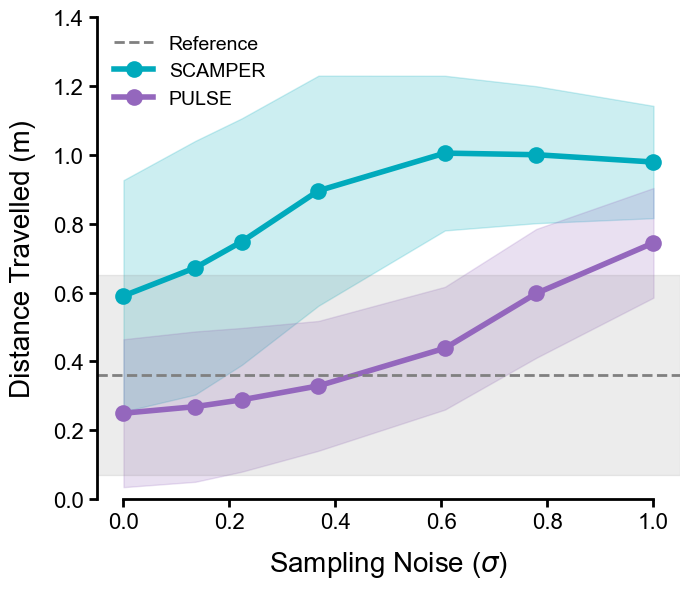

In [16]:
import matplotlib
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)  # tab:purple, matching Distill


# Keep only prior_logvar and prior_deterministic datasets (fixed noise levels)
plot_df = df[np.isfinite(df["sort_key"])].copy()
plot_df["noise_std"] = plot_df["sort_key"]

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=plot_df[plot_df["method"] == LABEL_A],
    x="noise_std",
    y="distance",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_a,
    label=LABEL_A,
    ax=ax,
)

sns.lineplot(
    data=plot_df[plot_df["method"] == LABEL_B],
    x="noise_std",
    y="distance",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_b,
    label=LABEL_B,
    ax=ax,
)

# Original (reference) baseline with shaded ±1 SD
if original_dist is not None:
    ref_mean = original_dist.mean()
    ref_std = original_dist.std()
    ax.axhline(
        ref_mean,
        color="gray",
        linestyle="--",
        linewidth=2,
        label="Reference",
    )
    xlim = ax.get_xlim()
    ax.axhspan(
        ref_mean - ref_std,
        ref_mean + ref_std,
        color="gray",
        alpha=0.15,
    )
    ax.set_xlim(xlim)

ax.set_ylim(0, 1.4)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Distance Travelled (m)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
handles, labels = ax.get_legend_handles_labels()
order = sorted(range(len(labels)), key=lambda i: (labels[i] != "Reference",))
ax.legend([handles[i] for i in order], [labels[i] for i in order], fontsize=14, frameon=False)

sns.despine(ax=ax)

# Trim spines to tick/ylim range
xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(0, 1.4)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{SAVE_NAME}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / SAVE_NAME}.[pdf|svg|png]")

plt.show()

## Net Displacement

Net displacement measures the straight-line distance from start to end of each rollout,
capturing how far the rodent actually walked rather than total path length.

In [17]:
def calculate_net_displacement(qpos: np.ndarray) -> np.ndarray:
    """Calculate straight-line distance from start to end for each rollout.

    Args:
        qpos: Shape (num_rollouts, num_steps, qpos_dim) - first 2 elements are x, y.

    Returns:
        displacements: Shape (num_rollouts,) - net displacement per rollout.
    """
    return np.linalg.norm(qpos[:, -1, :2] - qpos[:, 0, :2], axis=1)


def build_displacement_df(qpos_datasets, logvars, method_label):
    """Build a DataFrame of per-clip net displacements for all noise levels."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        displacements = calculate_net_displacement(qpos)
        for clip_idx, disp in enumerate(displacements):
            rows.append(
                {
                    "method": method_label,
                    "dataset": ds_name,
                    "std": info["std"],
                    "sort_key": info["sort_key"],
                    "label": info["label"],
                    "clip_idx": clip_idx,
                    "displacement": disp,
                }
            )
    return pd.DataFrame(rows)


disp_df_a = build_displacement_df(qpos_a, logvars_a, LABEL_A)
disp_df_b = build_displacement_df(qpos_b, logvars_b, LABEL_B)
disp_df = pd.concat([disp_df_a, disp_df_b], ignore_index=True)

# Original (reference) baseline
original_disp = None
if original_qpos is not None:
    original_disp = calculate_net_displacement(original_qpos)
    print(f"Original (reference) net displacement: mean={original_disp.mean():.2f} +/- {original_disp.std():.2f}")

print(f"Total rollouts: {len(disp_df)} ({LABEL_A}: {len(disp_df_a)}, {LABEL_B}: {len(disp_df_b)})")

Original (reference) net displacement: mean=0.21 +/- 0.22
Total rollouts: 15998 (SCAMPER: 7578, PULSE: 8420)


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_net_displacement.[pdf|svg|png]


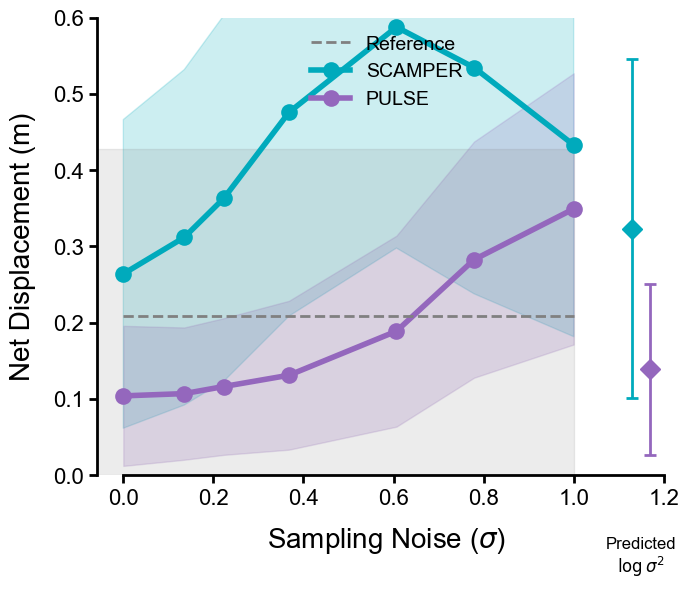

In [21]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)  # tab:purple, matching Distill

dplot_df = disp_df[np.isfinite(disp_df["sort_key"])].copy()
dplot_df["noise_std"] = dplot_df["sort_key"]

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=dplot_df[dplot_df["method"] == LABEL_A],
    x="noise_std",
    y="displacement",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_a,
    label=LABEL_A,
    ax=ax,
)

sns.lineplot(
    data=dplot_df[dplot_df["method"] == LABEL_B],
    x="noise_std",
    y="displacement",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_b,
    label=LABEL_B,
    ax=ax,
)

# Predicted logvar points
pred_x = dplot_df["noise_std"].max() + 0.15
pred_df = disp_df[disp_df["label"] == "predicted"]
for method, color, offset in [(LABEL_A, color_a, -0.02), (LABEL_B, color_b, 0.02)]:
    mdf = pred_df[pred_df["method"] == method]["displacement"]
    if len(mdf) > 0:
        ax.errorbar(
            pred_x + offset,
            mdf.mean(),
            yerr=mdf.std(),
            fmt="D",
            markersize=10,
            color=color,
            capsize=4,
            capthick=2,
            elinewidth=2,
            zorder=5,
        )
ax.annotate(
    "Predicted\n$\\log\\sigma^2$",
    xy=(pred_x, 0),
    xytext=(pred_x, -0.08),
    fontsize=12,
    ha="center",
    va="top",
    annotation_clip=False,
)

# Original (reference) baseline with shaded ±1 SD
if original_disp is not None:
    ref_mean = original_disp.mean()
    ref_std = original_disp.std()
    ax.plot(
        [0, 1.0],
        [ref_mean, ref_mean],
        color="gray",
        linestyle="--",
        linewidth=2,
        label="Reference",
    )
    xlim = ax.get_xlim()
    ax.axhspan(
        max(ref_mean - ref_std, 0),
        ref_mean + ref_std,
        xmin=0,
        xmax=(1.0 - xlim[0]) / (xlim[1] - xlim[0]),
        color="gray",
        alpha=0.15,
    )
    ax.set_xlim(xlim)

ax.set_ylim(0, 0.6)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Net Displacement (m)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
handles, labels = ax.get_legend_handles_labels()
order = sorted(range(len(labels)), key=lambda i: (labels[i] != "Reference",))
ax.legend([handles[i] for i in order], [labels[i] for i in order], fontsize=14, frameon=False)

sns.despine(ax=ax)

# Trim spines to tick/ylim range
xticks = ax.get_xticks()
yticks = ax.get_yticks()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.spines["left"].set_bounds(0, 0.6)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
disp_save = f"{SAVE_NAME}_net_displacement"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{disp_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / disp_save}.[pdf|svg|png]")

plt.show()


## Rearing Transition Analysis

Detect rearing events by counting threshold crossings on the root z-position (`qpos[:, 2]`).
Use the cells below to find a rearing clip, tune the threshold, then plot transitions vs noise level.

In [21]:
# Render z-position over time for a few clips to find rearing behaviour.
# Pick a dataset and a range of clip indices to inspect.
INSPECT_DATASET = "prior_logvar_0_qpos"  # high noise is more likely to rear
INSPECT_CLIPS = range(0, 16)  # adjust to browse more clips

inspect_qpos = qpos_a[INSPECT_DATASET]  # change to qpos_b to inspect the other file

ncols = 4
nrows = int(np.ceil(len(INSPECT_CLIPS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)

for idx, clip_idx in enumerate(INSPECT_CLIPS):
    ax = axes[idx // ncols][idx % ncols]
    z = inspect_qpos[clip_idx, :, 2]
    ax.plot(z, linewidth=1)
    ax.set_title(f"clip {clip_idx}", fontsize=10)
    ax.set_ylabel("z")
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(len(INSPECT_CLIPS), nrows * ncols):
    axes[idx // ncols][idx % ncols].set_visible(False)

plt.suptitle(f"Root z-position — {INSPECT_DATASET}", fontsize=13)
plt.tight_layout()
plt.show()

KeyError: 'prior_logvar_0_qpos'

In [22]:
import os

os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import mujoco
import mediapy as media
from scamper.environment.rodent import imitation
from scamper.environment import wrappers as vnl_wrappers
from scamper.environment.reference_clips import ReferenceClips
import cv2

# ============ RENDER CONFIGURATION ============
RENDER_CLIP = 8  # <-- set to a clip index that shows rearing
RENDER_DATASET = INSPECT_DATASET
RENDER_QPOS_SOURCE = qpos_a  # change to qpos_b for the other file
REFERENCE_DATA_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5"
CAMERA_NAME = "close_profile-rodent"
RENDER_FPS = 50
RENDER_HEIGHT = 480
RENDER_WIDTH = 640

# Create environment for rendering
reference_clips = ReferenceClips(data_path=REFERENCE_DATA_PATH, n_frames_per_clip=250)
env = vnl_wrappers.FlattenObsWrapper(imitation.Imitation(clips=reference_clips))
mj_model = env.mj_model
mj_data = mujoco.MjData(mj_model)
renderer = mujoco.Renderer(mj_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

# Render with timestep overlay
qpos_traj = RENDER_QPOS_SOURCE[RENDER_DATASET][RENDER_CLIP]
frames = []

for t, qpos in enumerate(qpos_traj):
    mj_data.qpos[:] = qpos
    mujoco.mj_forward(mj_model, mj_data)
    renderer.update_scene(mj_data, camera=CAMERA_NAME)
    frame = renderer.render().copy()

    # Burn in timestep text

    cv2.putText(
        frame,
        f"t={t}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.0,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    frames.append(frame)

renderer.close()

print(f"Rendered clip {RENDER_CLIP} from {RENDER_DATASET}: {len(frames)} frames")
media.show_video(frames, fps=RENDER_FPS)

KeyboardInterrupt: 

In [23]:
# Tune the rearing threshold on a specific clip.
# Set REARING_CLIP to a clip index that shows rearing from the grid above.
REARING_CLIP = 8  # <-- update after inspecting the grid
REARING_THRESHOLD = 0.10  # <-- adjust this
DOUBLE_CROSSING = False  # True: require up+down crossing pair per event; False: count every crossing
MIN_REARING_DURATION = 50  # minimum timesteps above threshold to count as a rearing event

z = inspect_qpos[REARING_CLIP, :, 2]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(z, linewidth=1.5, label="z-position")
ax.axhline(REARING_THRESHOLD, color="r", linestyle="--", linewidth=2, label=f"threshold = {REARING_THRESHOLD}")

# Mark crossings
above = (z > REARING_THRESHOLD).astype(int)
crossings = np.where(np.diff(above) != 0)[0] + 1
for c in crossings:
    ax.axvline(c, color="gray", alpha=0.4, linewidth=0.8)

ax.set_xlabel("Timestep")
ax.set_ylabel("Root z-position")
ax.set_title(f"Clip {REARING_CLIP} — {len(crossings)} threshold crossings")
ax.set_xticks(range(0, 501, 10))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Threshold crossings: {len(crossings)}")
print(f"Rearing transitions (enter + exit): {len(crossings)}")


NameError: name 'inspect_qpos' is not defined

In [20]:
def count_rearing_transitions(qpos, threshold, double_crossing=True, min_duration=1):
    """Count rearing events from z-position threshold crossings.

    Args:
        qpos: Shape (num_clips, num_steps, qpos_dim).
        threshold: z-position threshold for rearing.
        double_crossing: If True, require up+down pair per event.
        min_duration: Minimum consecutive timesteps above threshold to count as rearing.

    Returns:
        counts: Shape (num_clips,) — number of rearing events per clip.
    """
    z = qpos[:, :, 2]  # (num_clips, num_steps)
    above = (z > threshold).astype(np.int8)

    if min_duration <= 1:
        # Original fast path: just count crossings
        crossings = np.abs(np.diff(above, axis=1))
        counts = crossings.sum(axis=1)
        if double_crossing:
            counts = counts // 2
        return counts

    # Filter out short above-threshold runs
    counts = np.zeros(qpos.shape[0], dtype=int)
    for i in range(qpos.shape[0]):
        seq = above[i]
        # Find contiguous runs of above-threshold
        diffs = np.diff(np.concatenate(([0], seq, [0])))
        starts = np.where(diffs == 1)[0]
        ends = np.where(diffs == -1)[0]
        durations = ends - starts
        counts[i] = np.sum(durations >= min_duration)
    return counts


def build_rearing_df(qpos_datasets, logvars, method_label, threshold, double_crossing=True, min_duration=1):
    """Build a DataFrame of per-clip rearing transitions for all noise levels."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        transitions = count_rearing_transitions(qpos, threshold, double_crossing, min_duration)
        for clip_idx, n in enumerate(transitions):
            rows.append(
                {
                    "method": method_label,
                    "dataset": ds_name,
                    "std": info["std"],
                    "sort_key": info["sort_key"],
                    "label": info["label"],
                    "clip_idx": clip_idx,
                    "transitions": int(n),
                }
            )
    return pd.DataFrame(rows)


rdf_a = build_rearing_df(qpos_a, logvars_a, LABEL_A, REARING_THRESHOLD, DOUBLE_CROSSING, MIN_REARING_DURATION)
rdf_b = build_rearing_df(qpos_b, logvars_b, LABEL_B, REARING_THRESHOLD, DOUBLE_CROSSING, MIN_REARING_DURATION)
rdf = pd.concat([rdf_a, rdf_b], ignore_index=True)

# Original (reference) baseline
original_trans = None
if original_qpos is not None:
    original_trans = count_rearing_transitions(original_qpos, REARING_THRESHOLD, DOUBLE_CROSSING, MIN_REARING_DURATION)
    print(f"Original (reference) rearing transitions: mean={original_trans.mean():.2f} +/- {original_trans.std():.2f}")

print(f"\nTotal rollouts: {len(rdf)}")


NameError: name 'REARING_THRESHOLD' is not defined

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_rearing.[pdf|svg|png]


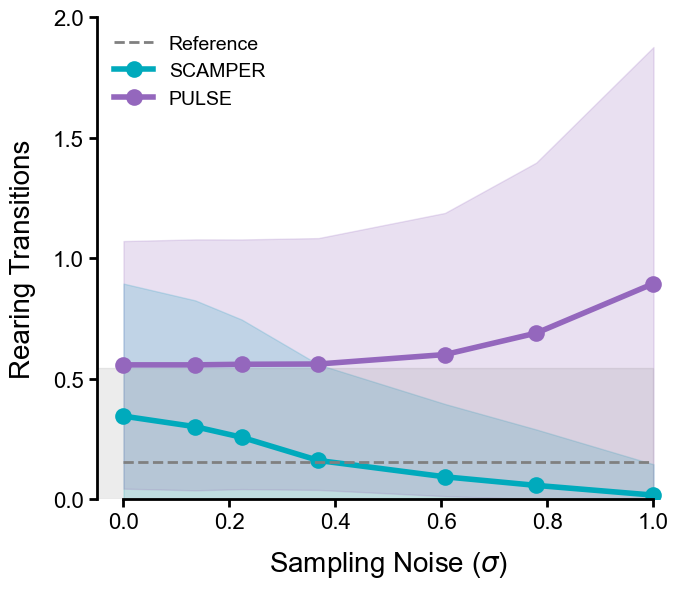

In [25]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)  # tab:purple, matching Distill

rplot_df = rdf[np.isfinite(rdf["sort_key"])].copy()
rplot_df["noise_std"] = rplot_df["sort_key"]

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=rplot_df[rplot_df["method"] == LABEL_A],
    x="noise_std",
    y="transitions",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_a,
    label=LABEL_A,
    ax=ax,
)

sns.lineplot(
    data=rplot_df[rplot_df["method"] == LABEL_B],
    x="noise_std",
    y="transitions",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_b,
    label=LABEL_B,
    ax=ax,
)

# Clip error band shading to y >= 0
for child in ax.get_children():
    if isinstance(child, plt.matplotlib.collections.PolyCollection):
        paths = child.get_paths()
        for path in paths:
            path.vertices[:, 1] = np.clip(path.vertices[:, 1], 0, None)

# Original (reference) baseline with shaded \u00b11 SD
if original_trans is not None:
    ref_mean = original_trans.mean()
    ref_std = original_trans.std()
    ax.plot(
        [0, 1.0],
        [ref_mean, ref_mean],
        color="gray",
        linestyle="--",
        linewidth=2,
        label="Reference",
    )
    xlim = ax.get_xlim()
    ax.axhspan(
        max(ref_mean - ref_std, 0),
        ref_mean + ref_std,
        xmin=0,
        xmax=(1.0 - xlim[0]) / (xlim[1] - xlim[0]),
        color="gray",
        alpha=0.15,
    )
    ax.set_xlim(xlim)

ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Rearing Transitions", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
handles, labels = ax.get_legend_handles_labels()
order = sorted(range(len(labels)), key=lambda i: (labels[i] != "Reference",))
ax.legend([handles[i] for i in order], [labels[i] for i in order], fontsize=14, frameon=False)

sns.despine(ax=ax)

# Move bottom spine/x-axis up to y=0
ax.spines["bottom"].set_position(("data", 0))

xticks = ax.get_xticks()
yticks = ax.get_yticks()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax.set_ylim(0, 2.0)
ax.set_yticks([0.0, 0.5, 1.0, 1.5, 2.0])
ax.spines["left"].set_bounds(0, 2.0)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
rear_save = f"{SAVE_NAME}_rearing"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{rear_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / rear_save}.[pdf|svg|png]")

plt.show()

/tmp/ipykernel_2942996/4008701158.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_rearing_violin.[pdf|svg|png]


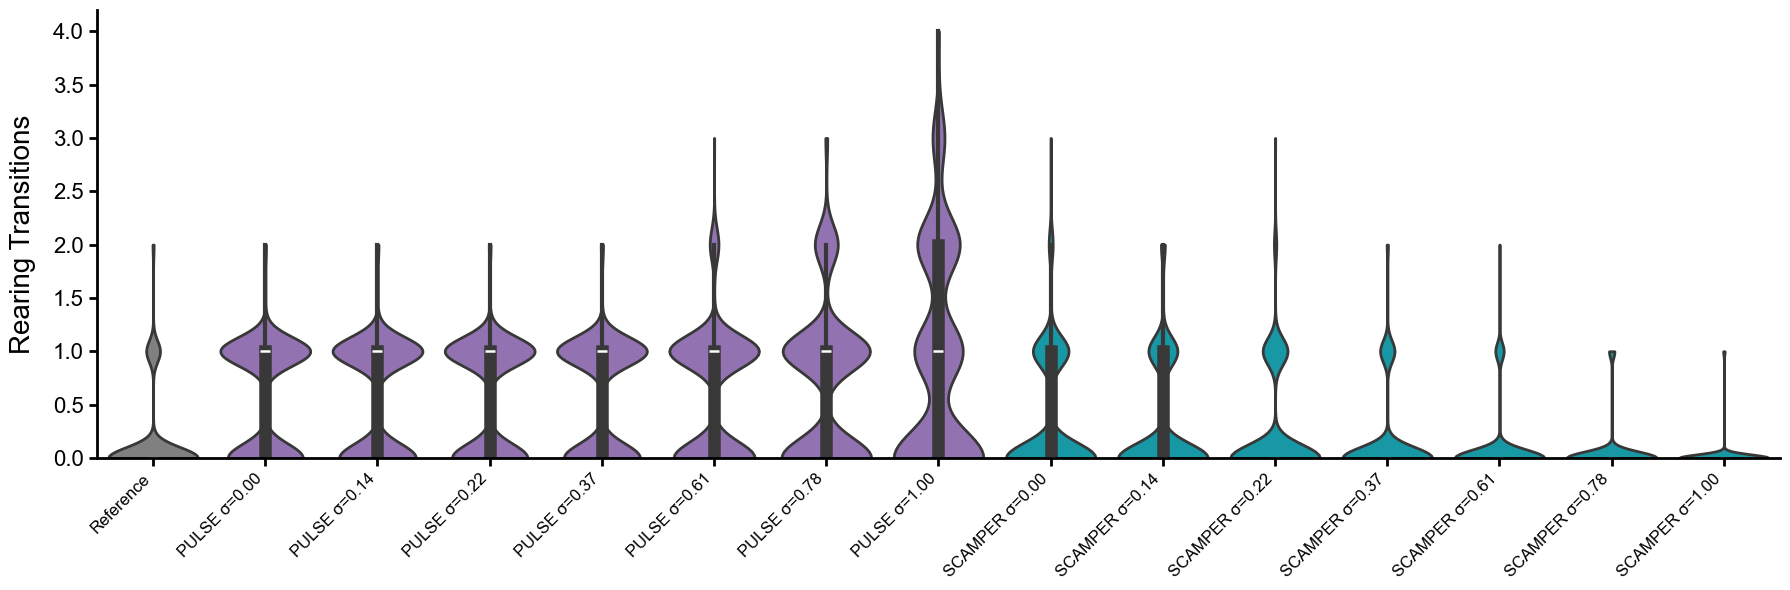

In [26]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

# Build violin DataFrame: one violin per (method, noise_std) + Reference
violin_rows = []
for _, row in rplot_df.iterrows():
    violin_rows.append({
        "group": f"{row['method']} \u03c3={row['noise_std']:.2f}",
        "method": row["method"],
        "noise_std": row["noise_std"],
        "transitions": row["transitions"],
    })
if original_trans is not None:
    for t in original_trans:
        violin_rows.append({
            "group": "Reference",
            "method": "Reference",
            "noise_std": -1,
            "transitions": int(t),
        })
violin_df = pd.DataFrame(violin_rows)

# Order: Reference first, then by method and noise_std
group_order = (
    violin_df.drop_duplicates("group")
    .sort_values(["method", "noise_std"])["group"]
    .tolist()
)
if "Reference" in group_order:
    group_order.remove("Reference")
    group_order.insert(0, "Reference")

# Palette
palette = {}
for g in group_order:
    if g == "Reference":
        palette[g] = "gray"
    elif g.startswith(LABEL_A):
        palette[g] = color_a
    else:
        palette[g] = color_b

fig, ax = plt.subplots(figsize=(max(len(group_order) * 1.2, 10), 6))

sns.violinplot(
    data=violin_df,
    x="group",
    y="transitions",
    order=group_order,
    palette=palette,
    inner="box",
    linewidth=2,
    cut=0,
    ax=ax,
)

ax.set_xlabel("", fontsize=20)
ax.set_ylabel("Rearing Transitions", fontsize=20, labelpad=12)
ax.tick_params(axis="y", labelsize=16, width=2, length=6)
ax.tick_params(axis="x", labelsize=12, width=2, length=6, rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_ylim(0, None)  # auto-scale top to fit all data

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
rear_violin_save = f"{SAVE_NAME}_rearing_violin"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{rear_violin_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / rear_violin_save}.[pdf|svg|png]")

plt.show()

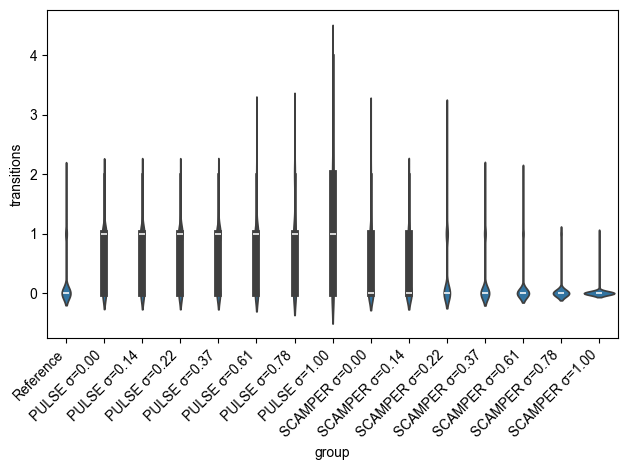

In [27]:
fig, ax = plt.subplots()
sns.violinplot(data=violin_df, x="group", y="transitions", order=group_order, ax=ax)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [19]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

# Pool all noise levels per method
ecdf_df = pd.DataFrame({
    "transitions": pd.concat([
        rplot_df.loc[rplot_df["method"] == LABEL_A, "transitions"],
        rplot_df.loc[rplot_df["method"] == LABEL_B, "transitions"],
        pd.Series(original_trans, name="transitions") if original_trans is not None else pd.Series(dtype=float),
    ], ignore_index=True),
    "group": (
        [LABEL_A] * (rplot_df["method"] == LABEL_A).sum()
        + [LABEL_B] * (rplot_df["method"] == LABEL_B).sum()
        + (["Reference"] * len(original_trans) if original_trans is not None else [])
    ),
})

fig, ax = plt.subplots(figsize=(7, 6))

sns.ecdfplot(data=ecdf_df[ecdf_df["group"] == "Reference"], x="transitions",
             color="gray", linestyle="--", linewidth=3, label="Reference", ax=ax)
sns.ecdfplot(data=ecdf_df[ecdf_df["group"] == LABEL_A], x="transitions",
             color=color_a, linewidth=3, label=LABEL_A, ax=ax)
sns.ecdfplot(data=ecdf_df[ecdf_df["group"] == LABEL_B], x="transitions",
             color=color_b, linewidth=3, label=LABEL_B, ax=ax)

ax.set_xlabel("Rearing Transitions", fontsize=20, labelpad=12)
ax.set_ylabel("Cumulative Proportion", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False)

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
ecdf_save = f"{SAVE_NAME}_rearing_ecdf"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{ecdf_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / ecdf_save}.[pdf|svg|png]")

plt.show()

NameError: name 'rplot_df' is not defined

In [34]:
print(original_trans.value_counts() if hasattr(original_trans, 'value_counts') else np.unique(original_trans, return_counts=True))

(array([0, 1, 2]), array([655, 184,   3]))


## Rearing Duration Distribution

Distribution of how long each rearing event lasts (in timesteps above threshold).
Filters out events shorter than `MIN_REARING_DURATION`.

In [9]:
def get_rearing_durations(qpos, threshold, min_duration=1):
    """Get durations of all rearing events across clips.

    Args:
        qpos: Shape (num_clips, num_steps, qpos_dim).
        threshold: z-position threshold for rearing.
        min_duration: Minimum timesteps to count as a rearing event.

    Returns:
        durations: 1D array of rearing event durations.
    """
    z = qpos[:, :, 2]
    above = (z > threshold).astype(np.int8)
    all_durations = []
    for i in range(qpos.shape[0]):
        diffs = np.diff(np.concatenate(([0], above[i], [0])))
        starts = np.where(diffs == 1)[0]
        ends = np.where(diffs == -1)[0]
        durations = ends - starts
        all_durations.extend(durations[durations >= min_duration])
    return np.array(all_durations)


def get_rearing_durations_by_noise(qpos_datasets, logvars, method_label, threshold, min_duration=1):
    """Get rearing durations grouped by noise level."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        if not np.isfinite(info["sort_key"]):
            continue
        durations = get_rearing_durations(qpos, threshold, min_duration)
        for d in durations:
            rows.append({
                "method": method_label,
                "noise_std": info["sort_key"],
                "duration": d * DT,
            })
    return pd.DataFrame(rows)


DT = 0.02  # seconds per timestep for generated clips (50 FPS)
DT_REF = DT * (490 / 250)  # reference mocap is at half the frequency

# All rearing durations (pooled across noise levels)
dur_a = get_rearing_durations_by_noise(qpos_a, logvars_a, LABEL_A, REARING_THRESHOLD, MIN_REARING_DURATION)
dur_b = get_rearing_durations_by_noise(qpos_b, logvars_b, LABEL_B, REARING_THRESHOLD, MIN_REARING_DURATION)
dur_df = pd.concat([dur_a, dur_b], ignore_index=True)

# Reference durations
ref_durations = None
if original_qpos is not None:
    ref_durations = get_rearing_durations(original_qpos, REARING_THRESHOLD, MIN_REARING_DURATION) * DT_REF
    print(f"Reference rearing durations: {len(ref_durations)} events, "
          f"mean={ref_durations.mean():.2f} +/- {ref_durations.std():.2f} s")

print(f"{LABEL_A}: {len(dur_a)} events, {LABEL_B}: {len(dur_b)} events")


NameError: name 'REARING_THRESHOLD' is not defined

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_rearing_duration.[pdf|svg|png]


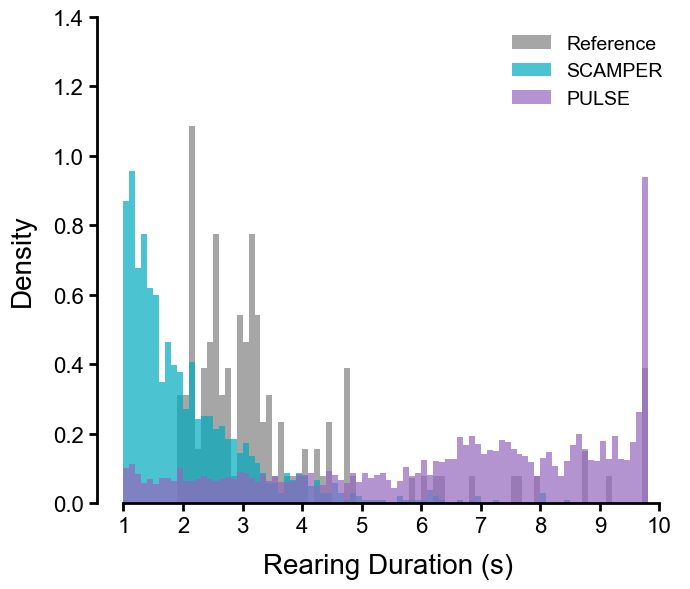

In [30]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

fig, ax = plt.subplots(figsize=(7, 6))

# Wider bins to reduce noise
bin_width = 0.1  # seconds
max_dur = dur_df["duration"].max()
bins = np.arange(MIN_REARING_DURATION * DT, max_dur + bin_width + 0.01, bin_width)

if ref_durations is not None and len(ref_durations) > 0:
    ax.hist(
        ref_durations,
        bins=bins,
        density=True,
        alpha=0.7,
        color="gray",
        label="Reference",
        edgecolor="none",
    )

ax.hist(
    dur_df[dur_df["method"] == LABEL_A]["duration"],
    bins=bins,
    density=True,
    alpha=0.7,
    color=color_a,
    label=LABEL_A,
    edgecolor="none",
)

ax.hist(
    dur_df[dur_df["method"] == LABEL_B]["duration"],
    bins=bins,
    density=True,
    alpha=0.7,
    color=color_b,
    label=LABEL_B,
    edgecolor="none",
)

ax.set_xticks(np.arange(MIN_REARING_DURATION * DT, 10.01, 1.0))
ax.set_xlabel("Rearing Duration (s)", fontsize=20, labelpad=12)
ax.set_ylabel("Density", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False)

sns.despine(ax=ax)

xticks = ax.get_xticks()
yticks = ax.get_yticks()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
ax.spines["bottom"].set_bounds(bins[0], 10)
ax.set_ylim(0, 1.4)
ax.spines["left"].set_bounds(0, 1.4)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
dur_save = f"{SAVE_NAME}_rearing_duration"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{dur_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / dur_save}.[pdf|svg|png]")

plt.show()


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_rearing_stacked_bar.[pdf|svg|png]


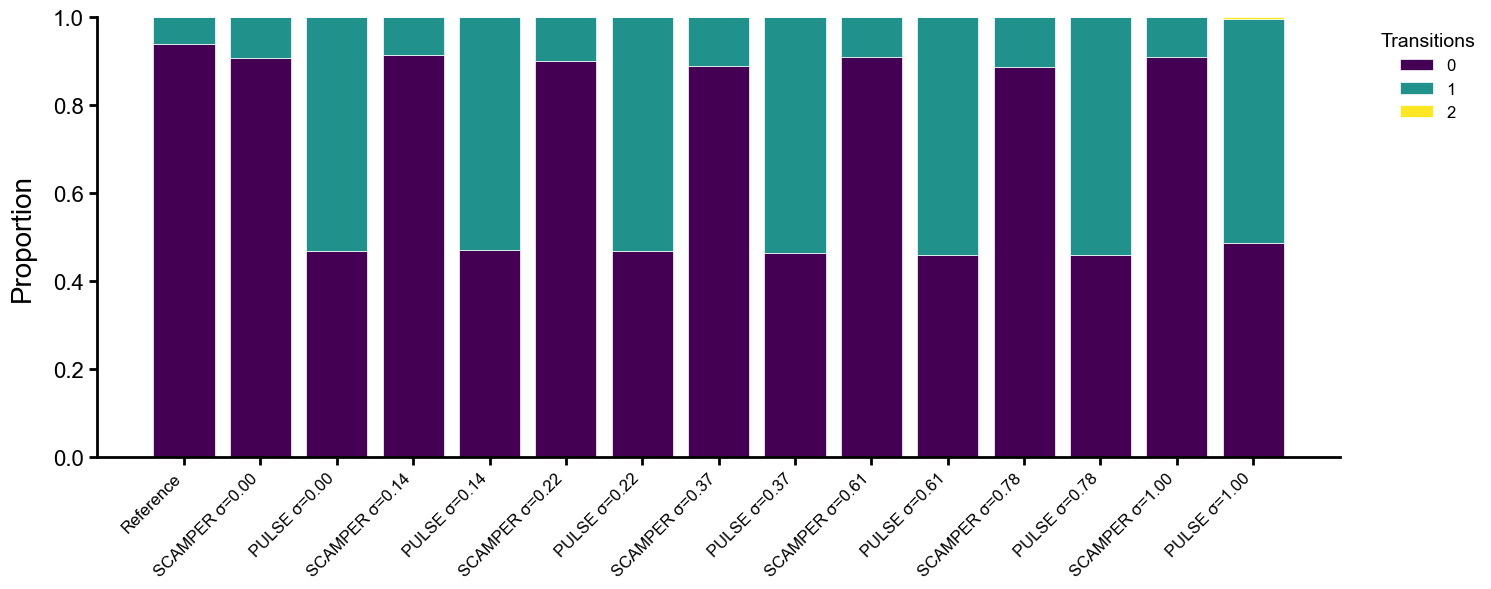

In [66]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

# Get all unique noise levels and max transition count
noise_levels = sorted(rplot_df["noise_std"].unique())
max_trans = int(rplot_df["transitions"].max())
if original_trans is not None:
    max_trans = max(max_trans, int(original_trans.max()))
trans_values = list(range(max_trans + 1))

# Build proportion data for each group
groups = []
if original_trans is not None:
    ref_counts = np.bincount(original_trans.astype(int), minlength=max_trans + 1)
    ref_props = ref_counts / ref_counts.sum()
    groups.append(("Reference", ref_props))

for noise in noise_levels:
    for method in [LABEL_A, LABEL_B]:
        mask = (rplot_df["method"] == method) & (rplot_df["noise_std"] == noise)
        vals = rplot_df.loc[mask, "transitions"].values.astype(int)
        if len(vals) == 0:
            continue
        counts = np.bincount(vals, minlength=max_trans + 1)
        props = counts / counts.sum()
        groups.append((f"{method} \u03c3={noise:.2f}", props))

group_names = [g[0] for g in groups]
prop_arrays = [g[1] for g in groups]

# Color map: one color per transition count
cmap = plt.cm.viridis
trans_colors = [cmap(i / max(max_trans, 1)) for i in trans_values]

fig, ax = plt.subplots(figsize=(max(len(group_names) * 1.0, 10), 6))

x = np.arange(len(group_names))
bottoms = np.zeros(len(group_names))

for t_val in trans_values:
    heights = [p[t_val] for p in prop_arrays]
    ax.bar(x, heights, bottom=bottoms, color=trans_colors[t_val],
           edgecolor="white", linewidth=0.5, label=str(t_val))
    bottoms += heights

ax.set_xticks(x)
ax.set_xticklabels(group_names, rotation=45, ha="right")
ax.set_ylabel("Proportion", fontsize=20, labelpad=12)
ax.set_xlabel("", fontsize=20)
ax.tick_params(axis="y", labelsize=16, width=2, length=6)
ax.tick_params(axis="x", labelsize=12, width=2, length=6)

# Legend for transition counts
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, title="Transitions", fontsize=12,
          title_fontsize=14, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
rear_bar_save = f"{SAVE_NAME}_rearing_stacked_bar"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{rear_bar_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / rear_bar_save}.[pdf|svg|png]")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_z_height_ecdf.[pdf|svg|png]


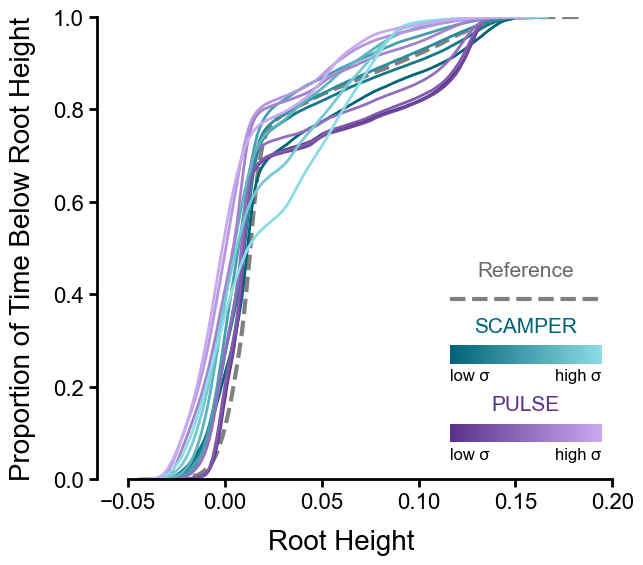

In [50]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

fig, ax = plt.subplots(figsize=(7, 6))

# Reference
if original_qpos is not None:
    z_ref = original_qpos[:, :, 2].ravel()
    z_ref = z_ref[z_ref >= -0.05]
    sns.ecdfplot(z_ref, color="gray", linestyle="--", linewidth=3, label="Reference", ax=ax)

# Get sorted noise levels for alpha mapping
noise_levels = sorted(set(
    parse_dataset_name(name, logvars_a)["sort_key"]
    for name in qpos_a
    if np.isfinite(parse_dataset_name(name, logvars_a)["sort_key"])
))

# Sequential colormaps per method: dark → light within each hue family
from matplotlib.colors import LinearSegmentedColormap

color_a_dark = (0 / 255, 100 / 255, 120 / 255)   # dark teal
color_a_light = (140 / 255, 220 / 255, 230 / 255) # light cyan
color_b_dark = (90 / 255, 50 / 255, 140 / 255)    # dark purple
color_b_light = (200 / 255, 170 / 255, 240 / 255) # light lavender

cmap_a = LinearSegmentedColormap.from_list('scamper', [color_a_dark, color_a_light])
cmap_b = LinearSegmentedColormap.from_list('pulse', [color_b_dark, color_b_light])

n_levels = len(noise_levels)
fracs = [i / max(n_levels - 1, 1) for i in range(n_levels)]

# Draw individual curves per noise level
for noise, frac in zip(noise_levels, fracs):
    std_label = f"\u03c3={noise:.2f}"
    # SCAMPER
    for name, qpos in qpos_a.items():
        info = parse_dataset_name(name, logvars_a)
        if info["sort_key"] == noise:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=cmap_a(frac), linewidth=2, ax=ax,
                         label="_nolegend_")
    # PULSE
    for name, qpos in qpos_b.items():
        info = parse_dataset_name(name, logvars_b)
        if info["sort_key"] == noise:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=cmap_b(frac), linewidth=2, ax=ax,
                         label="_nolegend_")

ax.set_xlabel("Root Height", fontsize=20, labelpad=12)
ax.set_ylabel("Proportion of Time Below Root Height", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)


# Legend: colorbars + labels using ax.text() for stable PDF rendering
import matplotlib.colors as mcolors

cbar_w = 0.28
cbar_h = 0.04
cbar_x = 1.0 - cbar_w - 0.02
base_y = 0.08
y_positions = [base_y, base_y + 0.17]  # PULSE, SCAMPER
ref_offset = 0.12  # smaller gap Reference-SCAMPER

legend_items = [
    (cmap_b, LABEL_B, color_b_dark),
    (cmap_a, LABEL_A, color_a_dark),
]

for i, (cmap, label, title_color) in enumerate(legend_items):
    y = y_positions[i]
    # Gradient bar
    cbar_ax = ax.inset_axes([cbar_x, y, cbar_w, cbar_h])
    gradient = np.linspace(0, 1, 256).reshape(1, -1)
    cbar_ax.imshow(gradient, aspect="auto", cmap=cmap)
    cbar_ax.set_axis_off()
    # Labels using ax.text (axes coords)
    ax.text(cbar_x + cbar_w / 2, y + cbar_h + 0.02, label,
            transform=ax.transAxes, fontsize=15, color=title_color,
            ha="center", va="bottom")
    ax.text(cbar_x, y - 0.01, "low \u03c3",
            transform=ax.transAxes, fontsize=12, ha="left", va="top")
    ax.text(cbar_x + cbar_w, y - 0.01, "high \u03c3",
            transform=ax.transAxes, fontsize=12, ha="right", va="top")

# Reference entry
ref_y = y_positions[1] + ref_offset
ref_ax = ax.inset_axes([cbar_x, ref_y, cbar_w, cbar_h])
ref_ax.plot([0, 1], [0.5, 0.5], color="gray", linestyle="--", linewidth=3,
            transform=ref_ax.transAxes, clip_on=False)
ref_ax.set_axis_off()
ax.text(cbar_x + cbar_w / 2, ref_y + cbar_h + 0.02, "Reference",
        transform=ax.transAxes, fontsize=15, color="dimgray",
        ha="center", va="bottom")

ax.set_xlim(-0.08, 0.20)
ax.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])

sns.despine(ax=ax)
ax.spines["left"].set_position(("axes", 0.05))
ax.spines["bottom"].set_bounds(-0.05, 0.20)
ax.spines["left"].set_bounds(0.0, 1.0)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)


# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
z_save = f"{SAVE_NAME}_z_height_ecdf"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{z_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / z_save}.[pdf|svg|png]")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_z_height_ecdf_predicted.[pdf|svg|png]


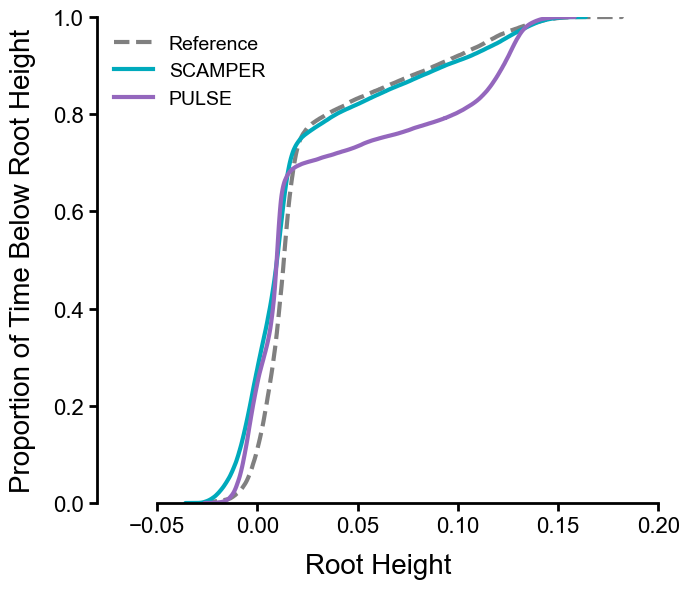

In [51]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

fig, ax = plt.subplots(figsize=(7, 6))

# Reference
if original_qpos is not None:
    z_ref = original_qpos[:, :, 2].ravel()
    z_ref = z_ref[z_ref >= -0.05]
    sns.ecdfplot(z_ref, color="gray", linestyle="--", linewidth=3, label="Reference", ax=ax)

# Predicted logvar curves
for method_label, qpos_datasets, logvars, color in [
    (LABEL_A, qpos_a, logvars_a, color_a),
    (LABEL_B, qpos_b, logvars_b, color_b),
]:
    for name, qpos in qpos_datasets.items():
        info = parse_dataset_name(name, logvars)
        if info["label"] == "predicted":
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=color, linewidth=3, label=method_label, ax=ax)

ax.set_xlabel("Root Height", fontsize=20, labelpad=12)
ax.set_ylabel("Proportion of Time Below Root Height", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False)

ax.set_xlim(-0.08, 0.20)
ax.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])

sns.despine(ax=ax)
ax.spines["bottom"].set_bounds(-0.05, 0.20)
ax.spines["left"].set_bounds(0.0, 1.0)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
z_save = f"{SAVE_NAME}_z_height_ecdf_predicted"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{z_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / z_save}.[pdf|svg|png]")

plt.show()


In [164]:
print(f"Reference: {original_qpos.shape}")
for name, qpos in sorted(qpos_a.items()):
    print(f"{LABEL_A} {name}: {qpos.shape}")
for name, qpos in sorted(qpos_b.items()):
    print(f"{LABEL_B} {name}: {qpos.shape}")

Reference: (842, 250, 74)
SCAMPER encoder_decoder_qpos: (842, 490, 74)
SCAMPER prior_deterministic_qpos: (842, 490, 74)
SCAMPER prior_logvar_-0.5_qpos: (842, 490, 74)
SCAMPER prior_logvar_-1_qpos: (842, 490, 74)
SCAMPER prior_logvar_-2_qpos: (842, 490, 74)
SCAMPER prior_logvar_-3_qpos: (842, 490, 74)
SCAMPER prior_logvar_-4_qpos: (842, 490, 74)
SCAMPER prior_logvar_0_qpos: (842, 490, 74)
SCAMPER prior_predicted_logvar_qpos: (842, 490, 74)
PULSE prior_deterministic_qpos: (842, 490, 74)
PULSE prior_logvar_-0.5_qpos: (842, 490, 74)
PULSE prior_logvar_-1_qpos: (842, 490, 74)
PULSE prior_logvar_-2_qpos: (842, 490, 74)
PULSE prior_logvar_-3_qpos: (842, 490, 74)
PULSE prior_logvar_-4_qpos: (842, 490, 74)
PULSE prior_logvar_0_qpos: (842, 490, 74)
PULSE prior_predicted_logvar_qpos: (842, 490, 74)
PULSE student_encoder_decoder_qpos: (842, 490, 74)
PULSE teacher_qpos: (842, 490, 74)


## Instantaneous Speed Distribution

Distribution of frame-to-frame speeds ($\|\Delta xy\| / \Delta t$) across all rollouts.
Captures the full velocity profile, not just aggregate displacement.

In [31]:
DT_GEN = 0.02  # seconds per timestep for generated clips (50 FPS)
DT_REF = DT_GEN * (490 / 250)  # reference mocap is at different frame count


def compute_speeds(qpos, dt):
    """Compute instantaneous speeds from qpos trajectories.

    Args:
        qpos: Shape (num_rollouts, num_steps, qpos_dim). First 2 dims are x, y.
        dt: Time between frames.

    Returns:
        speeds: 1D array of all frame-to-frame speeds.
    """
    dxy = np.diff(qpos[:, :, :2], axis=1)  # (num_rollouts, num_steps-1, 2)
    return np.linalg.norm(dxy, axis=2).ravel() / dt


# Compute reference speeds
ref_speeds = None
if original_qpos is not None:
    ref_speeds = compute_speeds(original_qpos, DT_REF)

# Compute speeds for each noise level
def build_speed_df(qpos_datasets, logvars, method_label, dt):
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        speeds = compute_speeds(qpos, dt)
        rows.append({
            "method": method_label,
            "dataset": ds_name,
            "label": info["label"],
            "sort_key": info["sort_key"],
            "speeds": speeds,
            "mean_speed": speeds.mean(),
            "median_speed": np.median(speeds),
            "std_speed": speeds.std(),
        })
    return rows

speed_rows_a = build_speed_df(qpos_a, logvars_a, LABEL_A, DT_GEN)
speed_rows_b = build_speed_df(qpos_b, logvars_b, LABEL_B, DT_GEN)

# Print summary
print(f"{'Method':<10} {'Dataset':<35} {'Mean':>8} {'Median':>8} {'Std':>8}")
for r in sorted(speed_rows_a + speed_rows_b, key=lambda x: (x["method"], x["sort_key"])):
    print(f"{r['method']:<10} {r['dataset']:<35} {r['mean_speed']:8.3f} {r['median_speed']:8.3f} {r['std_speed']:8.3f}")
if ref_speeds is not None:
    print(f"\nReference: mean={ref_speeds.mean():.3f}, median={np.median(ref_speeds):.3f}, std={ref_speeds.std():.3f}")


Method     Dataset                                 Mean   Median      Std
PULSE      prior_deterministic_qpos               0.025    0.011    0.051
PULSE      prior_logvar_-4_qpos                   0.035    0.021    0.056
PULSE      prior_logvar_-3_qpos                   0.043    0.031    0.054
PULSE      prior_logvar_-2_qpos                   0.059    0.047    0.055
PULSE      prior_logvar_-1_qpos                   0.088    0.076    0.064
PULSE      prior_logvar_-0.5_qpos                 0.112    0.099    0.079
PULSE      prior_logvar_0_qpos                    0.134    0.117    0.098
PULSE      prior_predicted_logvar_qpos            0.062    0.048    0.058
PULSE      student_encoder_decoder_qpos           0.048    0.024    0.060
PULSE      teacher_qpos                           0.049    0.026    0.060
SCAMPER    rgm_deterministic_qpos                 0.060    0.043    0.057
SCAMPER    rgm_logvar_-4_qpos                     0.073    0.057    0.060
SCAMPER    rgm_logvar_-3_qpos         

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_speed_distribution.[pdf|svg|png]


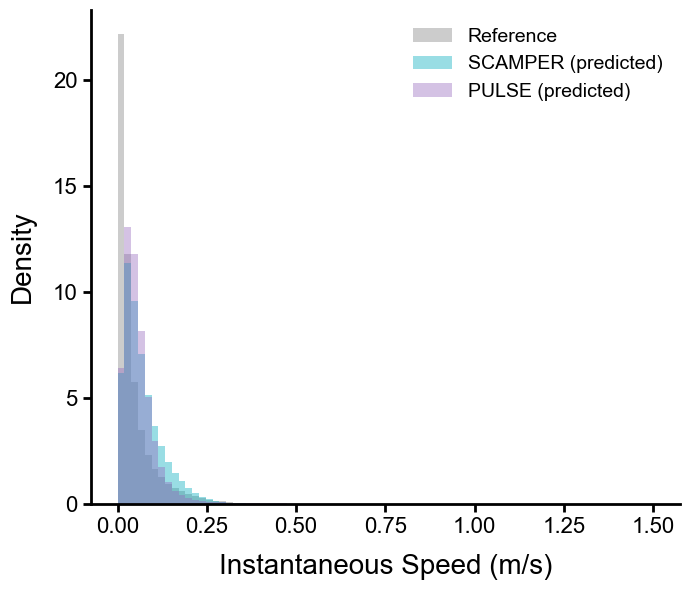

In [32]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

# Collect predicted logvar speeds for each method
pred_speeds_a = None
pred_speeds_b = None
for r in speed_rows_a:
    if r["label"] == "predicted":
        pred_speeds_a = r["speeds"]
for r in speed_rows_b:
    if r["label"] == "predicted":
        pred_speeds_b = r["speeds"]

fig, ax = plt.subplots(figsize=(7, 6))

bins = np.linspace(0, 1.5, 80)

if ref_speeds is not None:
    ax.hist(ref_speeds, bins=bins, density=True, alpha=0.4, color="gray",
            label="Reference", edgecolor="none")

if pred_speeds_a is not None:
    ax.hist(pred_speeds_a, bins=bins, density=True, alpha=0.4, color=color_a,
            label=f"{LABEL_A} (predicted)", edgecolor="none")

if pred_speeds_b is not None:
    ax.hist(pred_speeds_b, bins=bins, density=True, alpha=0.4, color=color_b,
            label=f"{LABEL_B} (predicted)", edgecolor="none")

ax.set_xlabel("Instantaneous Speed (m/s)", fontsize=20, labelpad=12)
ax.set_ylabel("Density", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False)

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
speed_save = f"{SAVE_NAME}_speed_distribution"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{speed_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / speed_save}.[pdf|svg|png]")

plt.show()


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/distance_vs_noise_comparison_mean_speed_vs_noise.[pdf|svg|png]


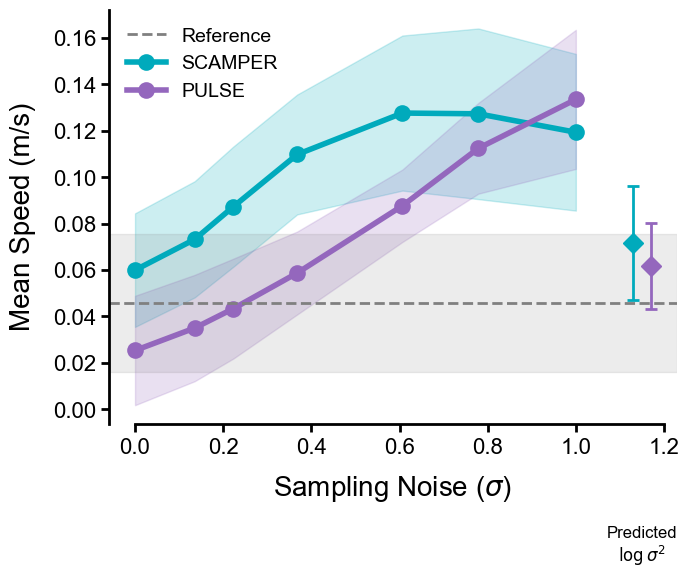

In [33]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

# Build per-clip mean speed dataframe for line plot
speed_clip_rows = []
for method_label, qpos_datasets, logvars, dt in [
    (LABEL_A, qpos_a, logvars_a, DT_GEN),
    (LABEL_B, qpos_b, logvars_b, DT_GEN),
]:
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        dxy = np.diff(qpos[:, :, :2], axis=1)
        clip_speeds = np.linalg.norm(dxy, axis=2).mean(axis=1) / dt  # per-clip mean speed
        for clip_idx, s in enumerate(clip_speeds):
            speed_clip_rows.append({
                "method": method_label,
                "sort_key": info["sort_key"],
                "label": info["label"],
                "clip_idx": clip_idx,
                "mean_speed": s,
            })

speed_clip_df = pd.DataFrame(speed_clip_rows)
splot_df = speed_clip_df[np.isfinite(speed_clip_df["sort_key"])].copy()
splot_df["noise_std"] = splot_df["sort_key"]

fig, ax = plt.subplots(figsize=(7, 6))

sns.lineplot(
    data=splot_df[splot_df["method"] == LABEL_A],
    x="noise_std",
    y="mean_speed",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_a,
    label=LABEL_A,
    ax=ax,
)

sns.lineplot(
    data=splot_df[splot_df["method"] == LABEL_B],
    x="noise_std",
    y="mean_speed",
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    color=color_b,
    label=LABEL_B,
    ax=ax,
)

# Predicted logvar points
pred_x = splot_df["noise_std"].max() + 0.15
pred_clip_df = speed_clip_df[speed_clip_df["label"] == "predicted"]
for method, color, offset in [(LABEL_A, color_a, -0.02), (LABEL_B, color_b, 0.02)]:
    mdf = pred_clip_df[pred_clip_df["method"] == method]["mean_speed"]
    if len(mdf) > 0:
        ax.errorbar(
            pred_x + offset,
            mdf.mean(),
            yerr=mdf.std(),
            fmt="D",
            markersize=10,
            color=color,
            capsize=4,
            capthick=2,
            elinewidth=2,
            zorder=5,
        )
ax.annotate(
    "Predicted\n$\\log\\sigma^2$",
    xy=(pred_x, 0),
    xytext=(pred_x, -0.05),
    fontsize=12,
    ha="center",
    va="top",
    annotation_clip=False,
)

# Reference baseline
if ref_speeds is not None:
    # Per-clip mean speeds for reference
    dxy_ref = np.diff(original_qpos[:, :, :2], axis=1)
    ref_clip_speeds = np.linalg.norm(dxy_ref, axis=2).mean(axis=1) / DT_REF
    ref_mean = ref_clip_speeds.mean()
    ref_std = ref_clip_speeds.std()
    ax.axhline(ref_mean, color="gray", linestyle="--", linewidth=2, label="Reference")
    xlim = ax.get_xlim()
    ax.axhspan(ref_mean - ref_std, ref_mean + ref_std, color="gray", alpha=0.15)
    ax.set_xlim(xlim)

ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Mean Speed (m/s)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
handles, labels = ax.get_legend_handles_labels()
order = sorted(range(len(labels)), key=lambda i: (labels[i] != "Reference",))
ax.legend([handles[i] for i in order], [labels[i] for i in order], fontsize=14, frameon=False)

sns.despine(ax=ax)

xticks = ax.get_xticks()
xlim = ax.get_xlim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ylim = ax.get_ylim()
ax.spines["left"].set_bounds(ylim[0], ylim[1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
speed_noise_save = f"{SAVE_NAME}_mean_speed_vs_noise"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{speed_noise_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / speed_noise_save}.[pdf|svg|png]")

plt.show()
